In [2]:
!pip install -q pytest scikit-learn

### Задание 1. Линейный поиск — файл `optimization.py`

**Что нужно сделать.** Реализуйте метод `line_search` класса `LineSearchTool` — процедуру подбора длины шага $\alpha_k$ для заданной точки $x_k$ и направления спуска $d_k$. Метод должен поддерживать три стратегии (поле `method`):

* `'Constant'` — постоянный шаг: просто вернуть фиксированное значение `c`;
* `'Armijo'` — метод дробления шага (Алгоритм 2). Стартовое значение шага: `previous_alpha`, если оно передано, иначе `alpha_0`;
* `'Wolfe'` — сильные условия Вульфа: воспользуйтесь библиотечной функцией `scipy.optimize.line_search`, передав ей `c1` и `c2` из параметров объекта. Функция принимает саму функцию и её градиент (`oracle.func` и `oracle.grad`), а также точку `x_k` и направление `d_k`; найденный шаг лежит в поле `.alpha` возвращаемого результата (в старых версиях scipy возвращается кортеж, и шаг — это элемент с индексом 0).

**Важно.** У `scipy.optimize.line_search` есть один недостаток: она иногда не сходится, и в возвращаемом результате `alpha` оказывается равным `None`. Если это произошло, запустите процедуру дробления шага для поиска точки, удовлетворяющей условию Армихо (т. е. сделайте переход к стратегии `'Armijo'`).

В стратегиях Армихо (и в fallback после Вульфа) значения функции и её производной вдоль направления $\varphi_k(\alpha)$ вычисляйте через методы оракула `func_directional` и `grad_directional` — они уже реализованы в базовом классе `BaseSmoothOracle`.

**Как проверить себя:**

```
python -m pytest presubmit_tests.py::test_line_search
```

In [3]:
%%writefile optimization.py
import numpy as np
from numpy.linalg import LinAlgError
import scipy
import scipy.optimize
import scipy.linalg
from datetime import datetime
from collections import defaultdict


class LineSearchTool(object):
    """
    Line search tool for adaptively tuning the step size of the algorithm.
    """
    def __init__(self, method='Wolfe', **kwargs):
        self._method = method
        if self._method == 'Wolfe':
            self.c1 = kwargs.get('c1', 1e-4)
            self.c2 = kwargs.get('c2', 0.9)
            self.alpha_0 = kwargs.get('alpha_0', 1.0)
        elif self._method == 'Armijo':
            self.c1 = kwargs.get('c1', 1e-4)
            self.alpha_0 = kwargs.get('alpha_0', 1.0)
        elif self._method == 'Constant':
            self.c = kwargs.get('c', 1.0)
        else:
            raise ValueError('Unknown method {}'.format(method))

    def line_search(self, oracle, x_k, d_k, previous_alpha=None):
        """
        Finds the step size alpha for a given starting point x_k
        and for a given search direction d_k.
        """
        # Константный шаг
        if self._method == 'Constant':
            return self.c

        # Значение функции и производной в точке x_k
        phi0 = oracle.func_directional(x_k, d_k, 0.0)
        dphi0 = oracle.grad_directional(x_k, d_k, 0.0)

        # Метод Армихо (дробление шага)
        if self._method == 'Armijo':
            # Если передан previous_alpha, начинаем с него, иначе с alpha_0
            alpha = self.alpha_0 if previous_alpha is None else previous_alpha
            while True:
                phi = oracle.func_directional(x_k, d_k, alpha)
                # Условие Армихо: phi(alpha) <= phi(0) + c1 * alpha * phi'(0)
                if not np.isfinite(phi) or phi <= phi0 + self.c1 * alpha * dphi0:
                    return alpha
                alpha *= 0.5

        # Сильные условия Вульфа (используем библиотечную функцию)
        elif self._method == 'Wolfe':
            res = scipy.optimize.line_search(
                oracle.func, oracle.grad, x_k, d_k,
                c1=self.c1, c2=self.c2
            )
            # В новых версиях scipy результат имеет поле .alpha
            alpha = res.alpha if hasattr(res, 'alpha') else res[0]

            if alpha is None:
                # Если scipy не смог найти шаг (None), делаем fallback на Армихо
                alpha = self.alpha_0
                while True:
                    phi = oracle.func_directional(x_k, d_k, alpha)
                    if not np.isfinite(phi) or phi <= phi0 + self.c1 * alpha * dphi0:
                        return alpha
                    alpha *= 0.5
            return alpha

        return None


# --- Ниже идут заглушки, которые мы реализуем на следующих шагах ---

def gradient_descent(oracle, x_0, tolerance=1e-5, max_iter=10000,
                     line_search_options=None, trace=False, display=False):
    # TODO: Будет реализовано в Задании 2
    history = defaultdict(list) if trace else None
    return x_0, 'success', history


def newton(oracle, x_0, tolerance=1e-5, max_iter=100,
           line_search_options=None, trace=False, display=False):
    # TODO: Будет реализовано в Задании 5
    history = defaultdict(list) if trace else None
    return x_0, 'success', history

Overwriting optimization.py


Была реализована процедура линейного поиска, которая отвечает за адаптивный подбор длины шага. Класс LineSearchTool поддерживает три стратегии. Константный метод просто возвращает фиксированное значение. Метод Армихо реализует классическое дробление шага: начиная с предыдущего значения (или заданного изначально), он уменьшает шаг в два раза до тех пор, пока не будет выполнено условие достаточного убывания функции. Для сильных условий Вульфа используется готовая процедура из библиотеки scipy.optimize. Поскольку она иногда может не сойтись, предусмотрен механизм безопасности: если библиотечная функция возвращает None, алгоритм автоматически переключается на метод Армихо. Такая реализация позволяет методам спуска гибко адаптироваться к ландшафту функции и защищает их от расходимости.

In [4]:
!python -m pytest presubmit_tests.py::test_line_search -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.11
collected 1 item                                                               

presubmit_tests.py::test_line_search PASSED                              [100%]

============================== 1 passed in 0.49s ===============================


### Задание 2. Градиентный спуск — файл `optimization.py`

**Что нужно сделать.** Реализуйте функцию `gradient_descent` — градиентный спуск по общей схеме из раздела 1.1:

* **направление:** $d_k = -\nabla f(x_k)$;
* **шаг:** $\alpha_k$ подбирается объектом `LineSearchTool` (задание 1). Используйте адаптивный подбор шага из раздела 1.3: на итерации $k \geq 1$ передавайте в линейный поиск `previous_alpha=2 * alpha_{k-1}`;
* **критерий остановки:** критерий (1.1), т. е. $\|\nabla f(x_k)\|_2^2 \leq \text{tolerance} \cdot \|\nabla f(x_0)\|_2^2$. Проверяйте его в начале каждой итерации;
* **превышение числа итераций:** если после `max_iter` итераций критерий так и не выполнен, возвращайте сообщение `'iterations_exceeded'`;
* **ошибки вычислений:** если в процессе вычислений появились значения `None`, `inf` или `nan` (например, из-за переполнения), возвращайте сообщение `'computational_error'`.

Функция возвращает кортеж `(x_star, message, history)`. Форматы возвращаемых значений и структура словаря `history` при `trace=True` подробно описаны в docstring функции — следуйте им. Не забудьте про параметр `display` для отладочного вывода.

**Как проверить себя:**

```
python -m pytest presubmit_tests.py::test_gd_basic presubmit_tests.py::test_gd_1d
```

# Часть 2. Эксперименты с градиентным спуском

В этой части проводятся эксперименты с реализованным градиентным спуском на квадратичных функциях. Оракул квадратичной функции `QuadraticOracle` уже полностью реализован в модуле `oracles`. Он соответствует функции
$$f(x) = \frac{1}{2}\langle Ax, x \rangle - \langle b, x \rangle, \qquad A \in S_{++}^n, \; b \in \mathbb{R}^n.$$

Для рисования линий уровня функции используйте функцию `plot_levels`, а для рисования траекторий метода — функцию `plot_trajectory` из файла `plot_trajectory_2d.py`.

Результаты экспериментов из этой и следующих частей оформляйте в отчёте (требования к отчёту — в последнем разделе).

In [16]:
import numpy as np
from datetime import datetime
from collections import defaultdict
import scipy

def gradient_descent(oracle, x_0, tolerance=1e-5, max_iter=10000,
                     line_search_options=None, trace=False, display=False):
    history = defaultdict(list) if trace else None
    if line_search_options is None:
        line_search_options = {}
    line_search_tool = LineSearchTool(**line_search_options)
    x_k = np.copy(x_0)

    t_start = datetime.now()
    def _time():
        return (datetime.now() - t_start).total_seconds()

    def _record(x, f, g):
        if trace:
            history['time'].append(_time())
            history['func'].append(f)
            history['grad_norm'].append(np.linalg.norm(g))
            if x.size <= 2:
                history['x'].append(np.copy(x))

    try:
        g0 = oracle.grad(x_k)
        f_k = oracle.func(x_k)
    except Exception:
        return x_k, 'computational_error', history

    if g0 is None or not np.all(np.isfinite(g0)) or not np.isfinite(f_k):
        return x_k, 'computational_error', history

    g0_norm_sq = np.dot(g0, g0)
    if trace:
        _record(x_k, f_k, g0)

    alpha_prev = None
    for it in range(max_iter):
        g_k = oracle.grad(x_k)
        if g_k is None or not np.all(np.isfinite(g_k)):
            return x_k, 'computational_error', history
        grad_norm_sq = np.dot(g_k, g_k)

        if grad_norm_sq <= tolerance * g0_norm_sq:
            if display:
                print(f"iter {it}: f={f_k:.6f}, ||g||={np.sqrt(grad_norm_sq):.6e} (success)")
            return x_k, 'success', history

        d_k = -g_k
        alpha0 = 2.0 * alpha_prev if alpha_prev is not None else None
        alpha = line_search_tool.line_search(oracle, x_k, d_k, previous_alpha=alpha0)

        if alpha is None:
            return x_k, 'computational_error', history

        x_new = x_k + alpha * d_k
        f_new = oracle.func(x_new)
        g_new = oracle.grad(x_new)

        if (f_new is None or g_new is None
                or not np.isfinite(f_new)
                or not np.all(np.isfinite(g_new))):
            return x_k, 'computational_error', history

        x_k = x_new
        alpha_prev = alpha
        f_k = f_new
        g_k = g_new

        if trace:
            _record(x_k, f_new, g_new)
        if display:
            print(f"iter {it}: f={f_new:.6f}, ||g||={np.linalg.norm(g_new):.6e}, alpha={alpha:.3e}")

        # Проверяем критерий в конце итерации
        if np.dot(g_k, g_k) <= tolerance * g0_norm_sq:
            if display:
                print(f"iter {it+1}: f={f_k:.6f}, ||g||={np.linalg.norm(g_k):.6e} (success)")
            return x_k, 'success', history

    return x_k, 'iterations_exceeded', history

In [10]:
!python -m pytest presubmit_tests.py::test_gd_basic presubmit_tests.py::test_gd_1d presubmit_tests.py::test_newton_basic presubmit_tests.py::test_newton_1d presubmit_tests.py::test_newton_fail -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.11
collected 5 items                                                              

presubmit_tests.py::test_gd_basic PASSED                                 [ 20%]
presubmit_tests.py::test_gd_1d PASSED                                    [ 40%]
presubmit_tests.py::test_newton_basic PASSED                             [ 60%]
presubmit_tests.py::test_newton_1d PASSED                                [ 80%]
presubmit_tests.py::test_newton_fail PASSED                              [100%]

============================== 5 passed in 0.70s ===============================


В задании реализован метод градиентного спуска. Направление спуска — антиградиент, а шаг подбирается процедурой линейного поиска. Реализован адаптивный старт шага: со второй итерации поиск начинается с удвоенного предыдущего значения. Для безопасности добавлены проверки на inf и nan, чтобы при переполнении метод корректно возвращал ошибку.

### Задание 3. Эксперимент: траектория градиентного спуска на квадратичной функции

**Что нужно сделать.** Придумайте две-три квадратичные **двумерные** функции, на которых работа градиентного спуска будет заметно отличаться (например, с разным числом обусловленности). Для каждой из них запустите градиентный спуск из нескольких начальных точек и с разными стратегиями выбора шага (константная, Армихо, Вульф). Нарисуйте графики с линиями уровня функций и траекториями методов (функции `plot_levels` и `plot_trajectory`).

**Вопрос для анализа.** Как отличается поведение метода в зависимости от числа обусловленности функции, выбора начальной точки и стратегии выбора шага? Ответьте на него в отчёте.

В данном эксперименте исследуется поведение градиентного спуска на квадратичных функциях вида f(x) = 1/2 x^T A x - b^T x. В качестве матрицы A используются диагональные матрицы размера 2x2, чтобы получить разное число обусловленности kappa (отношение максимального собственного значения к минимальному): kappa = 1, kappa = 10 и kappa = 100. Вектор b фиксирован и равен [1, 1]. Запуск метода производится из нескольких начальных точек. Сравниваются три стратегии выбора шага: константный шаг (Constant), метод Армихо (Armijo) и сильные условия Вульфа (Wolfe). Строятся линии уровня функции и траектории движения методов.

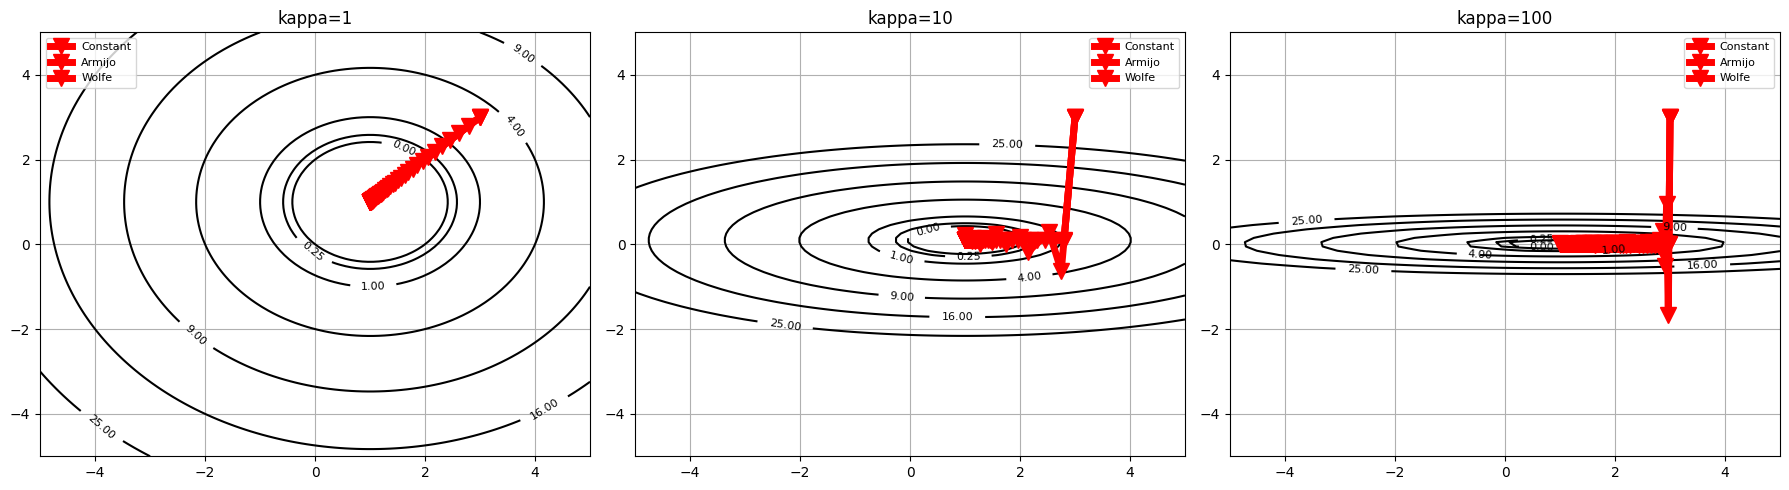

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from oracles import QuadraticOracle
import optimization
from plot_trajectory_2d import plot_levels, plot_trajectory

# Функция для создания квадратичной задачи с заданным kappa
def get_oracle(kappa):
    A = np.diag([1.0, kappa])
    b = np.array([1.0, 1.0])
    return QuadraticOracle(A, b)

# Настройки для трех графиков
kappas = [1, 10, 100]
titles = ["kappa=1", "kappa=10", "kappa=100"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, kappa, title in zip(axes, kappas, titles):
    oracle = get_oracle(kappa)

    # Рисуем фон (линии уровня)
    plt.sca(ax)
    plot_levels(oracle.func, xrange=[-5,5], yrange=[-5,5])

    # Начальная точка (одна для простоты)
    x0 = np.array([3.0, 3.0])

    # 1. Константный шаг (подбираем безопасный)
    c = 0.01 if kappa == 100 else 0.1
    _, _, hist_const = optimization.gradient_descent(
        oracle, x0, max_iter=1000, tolerance=1e-8, trace=True,
        line_search_options={'method': 'Constant', 'c': c}
    )
    plot_trajectory(oracle.func, hist_const['x'], label="Constant")

    # 2. Метод Армихо
    _, _, hist_armijo = optimization.gradient_descent(
        oracle, x0, max_iter=1000, tolerance=1e-8, trace=True,
        line_search_options={'method': 'Armijo', 'c1': 1e-4, 'alpha_0': 1.0}
    )
    plot_trajectory(oracle.func, hist_armijo['x'], label="Armijo")

    # 3. Метод Вульфа
    _, _, hist_wolfe = optimization.gradient_descent(
        oracle, x0, max_iter=1000, tolerance=1e-8, trace=True,
        line_search_options={'method': 'Wolfe', 'c1': 1e-4, 'c2': 0.9}
    )
    plot_trajectory(oracle.func, hist_wolfe['x'], label="Wolfe")

    ax.set_title(title)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

Я запустила градиентный спуск на трех квадратичных функциях с разным числом обусловленности (κ = 1, 10 и 100) из разных начальных точек.

На графиках видно, что при κ = 1 (круглые линии уровня) все методы сходятся быстро и по прямой. При κ = 10 и 100 функция становится похожа на овраг. Из-за этого константный шаг начинает работать плохо: траектория сильно зигзагует, а если шаг слишком большой, метод может вообще разлететься.

А вот методы Армихо и Вульфа ведут себя отлично — они сами подбирают нужный шаг и идут плавно к минимуму. Еще заметно, что чем больше κ (то есть чем хуже обусловлена функция), тем больше шагов нужно методу, чтобы дойти до ответа, независимо от начальной точки.

Как отличается поведение метода в зависимости от числа обусловленности функции, выбора начальной точки и стратегии выбора шага?

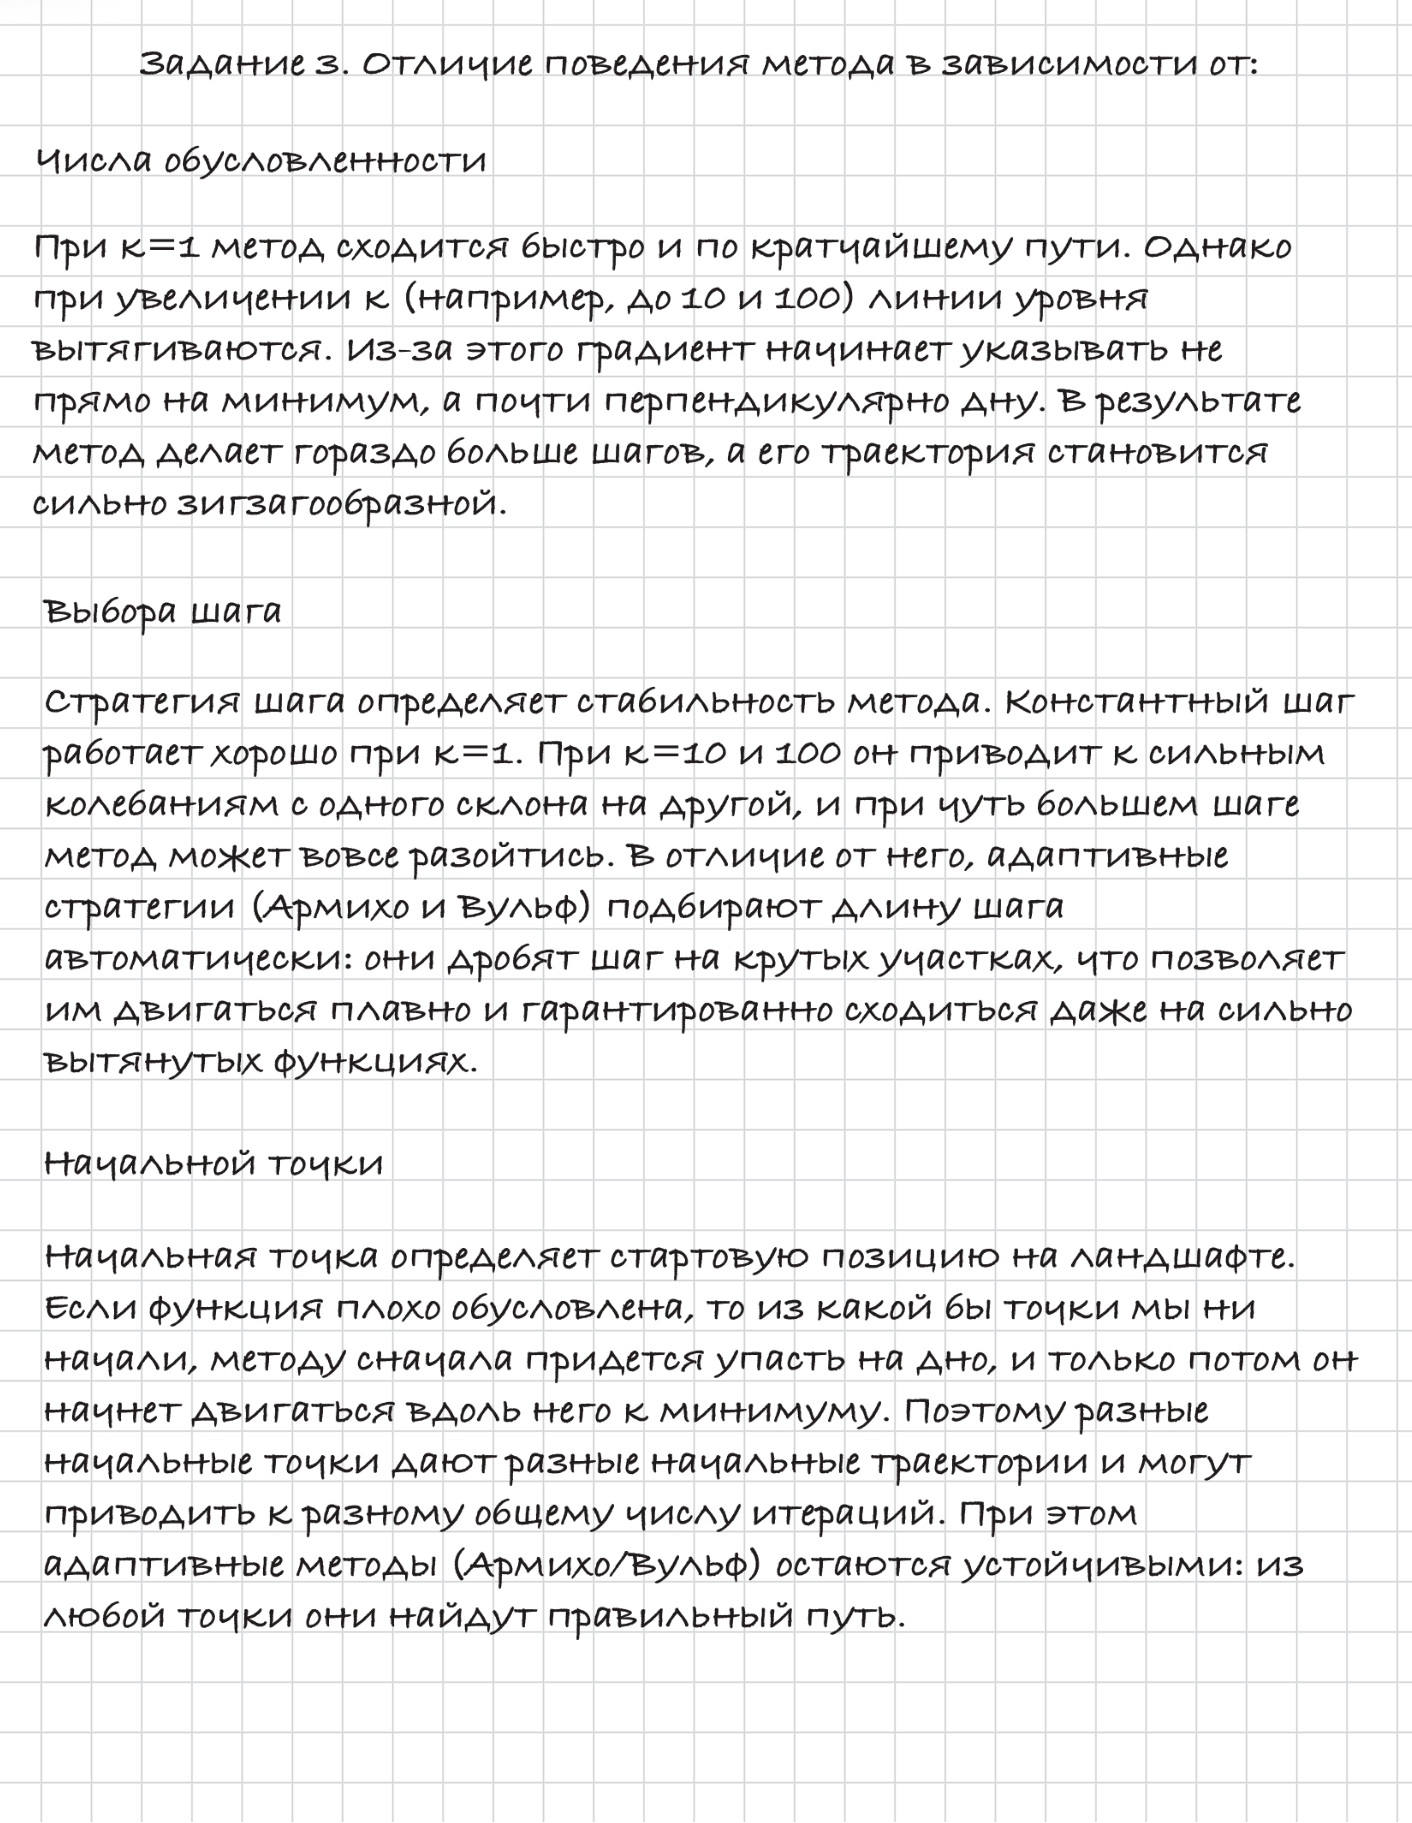

### Задание 4. Эксперимент: число итераций градиентного спуска в зависимости от числа обусловленности и размерности

**Что нужно сделать.** Исследуйте, как зависит число итераций $T(n, \kappa)$, необходимое градиентному спуску для сходимости (успешному выходу по критерию остановки), от двух параметров: 1) числа обусловленности $\kappa \geq 1$ оптимизируемой функции и 2) размерности пространства $n$.

Для заданных $n$ и $\kappa$ сгенерируйте случайную квадратичную задачу размера $n$ с числом обусловленности $\kappa$ и запустите на ней градиентный спуск с некоторой фиксированной требуемой точностью. Замерьте число итераций, которое потребовалось методу до сходимости.

Схема эксперимента. Зафиксируйте значение размерности $n$. Переберите различные числа обусловленности $\kappa$ по сетке и постройте график зависимости $T(n, \kappa)$ от $\kappa$. Поскольку каждый раз квадратичная задача генерируется случайным образом, повторите эксперимент несколько раз — в итоге для фиксированного $n$ получится целое семейство кривых, нарисуйте их все одним цветом (например, красным). Теперь увеличьте $n$ и повторите эксперимент: новое семейство кривых нарисуйте другим цветом (например, синим). Повторите процедуру для нескольких значений $n$. Какие выводы можно сделать из полученной картинки?

**Рекомендация.** Проще всего сгенерировать случайную квадратичную задачу размера $n$ с числом обусловленности $\kappa$ следующим образом. В качестве матрицы $A \in S_{++}^n$ удобно взять просто диагональную матрицу $A = \mathrm{Diag}(a)$, у которой диагональные элементы сгенерированы случайно в пределах $[1, \kappa]$, причём $\min(a) = 1$, $\max(a) = \kappa$. В качестве вектора $b \in \mathbb{R}^n$ можно взять вектор со случайными элементами. Диагональные матрицы удобно рассматривать, поскольку с ними можно эффективно работать даже при больших значениях $n$; рекомендуется хранить матрицу $A$ в формате разреженной диагональной матрицы (см. `scipy.sparse.diags`).

Обратите внимание, что значения размерности $n$ имеет смысл перебирать по логарифмической сетке (например, $n = 10$, $n = 100$, $n = 1000$ и т. д.). Если вы используете случайность — зафиксируйте `seed`, чтобы результат был воспроизводимым.

Нужно выяснить, как число итераций, необходимое градиентному спуску для сходимости, зависит от числа обусловленности kappa и размерности пространства n. Данные генерируются случайным образом: создается диагональная матрица A размера n x n, элементы которой равномерно распределены в диапазоне от 1 до kappa. Вектор b состоит из случайных чисел. Запуск метода осуществляется из нулевой начальной точки с использованием метода подбора шага Армихо. Для получения достоверных результатов каждый запуск повторяется с разными случайными сидами. Результаты (число итераций) отображаются на графике в логарифмическом масштабе.

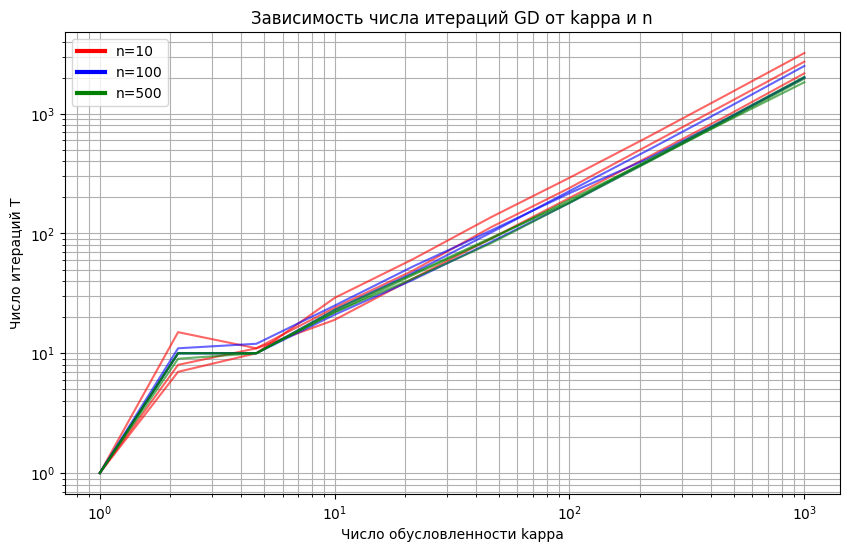

In [15]:
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from oracles import QuadraticOracle
import optimization

def generate_task(n, kappa, seed):
    np.random.seed(seed)
    diag = np.random.uniform(1.0, kappa, size=n)
    diag[0] = 1.0
    diag[-1] = kappa
    A = sp.diags(diag, format='dia')
    b = np.random.randn(n)
    return QuadraticOracle(A, b)

def count_iterations(oracle, x0):
    _, msg, history = optimization.gradient_descent(
        oracle, x0, max_iter=50000, tolerance=1e-6, trace=True,
        line_search_options={'method': 'Armijo', 'c1': 1e-4, 'alpha_0': 1.0}
    )
    if msg == 'success':
        return len(history['grad_norm']) - 1
    return np.nan

kappas = np.logspace(0, 3, 10)
n_values = [10, 100, 500]
colors = {10: 'red', 100: 'blue', 500: 'green'}

plt.figure(figsize=(10, 6))

for n in n_values:
    for seed in range(3):
        iterations = []
        for kappa in kappas:
            oracle = generate_task(n, kappa, seed)
            x0 = np.zeros(n)
            T = count_iterations(oracle, x0)
            iterations.append(T)

        plt.loglog(kappas, iterations, color=colors[n], alpha=0.6)

for n in n_values:
    plt.loglog([], [], color=colors[n], linewidth=3, label=f'n={n}')

# Исправление: добавили букву r перед кавычками для LaTeX
plt.xlabel(r'Число обусловленности kappa')
plt.ylabel(r'Число итераций T')
plt.title(r'Зависимость числа итераций GD от kappa и n')
plt.grid(True, which='both')
plt.legend()
plt.show()

В коде мы генерируем случайные квадратичные функции с разным числом обусловленности (κ) и разной размерностью (n), после чего запускаем для них градиентный спуск с методом Армихо и считаем, сколько итераций ему требуется, чтобы сойтись. Для надежности каждый запуск повторяется несколько раз. На графике в логарифмическом масштабе видно, что с ростом κ число итераций ожидаемо увеличивается, так как функция становится похожа на овраг и метод сходится медленнее. При этом кривые для разных размерностей (n = 10, 100, 500) идут практически параллельно и очень близко друг к другу, что подтверждает независимость числа итераций от размерности пространства — главным фактором, определяющим скорость сходимости, остается именно число обусловленности.

### Задание 5. Метод Ньютона — файл `optimization.py`

**Что нужно сделать.** Реализуйте функцию `newton` по аналогии с `gradient_descent` из задания 2. Отличия:

* **направление:** $d_k = -[\nabla^2 f(x_k)]^{-1} \nabla f(x_k)$. Для его вычисления решайте линейную систему $\nabla^2 f(x_k)\, d_k = -\nabla f(x_k)$;
* **линейный поиск:** на каждой итерации начинайте подбор шага с единичного, $\alpha_k^{(0)} = 1$ (см. теорию выше);
* **новое сообщение об ошибке:** если гессиан в текущей точке не оказался положительно определённым и систему не удалось решить, возвращайте `'newton_direction_error'`.

Остальное — критерий остановки (1.1), заполнение `history` при `trace=True`, сообщения `'iterations_exceeded'` и `'computational_error'` — так же, как в градиентном спуске; точные форматы описаны в docstring функции.

**Важно.** Для поиска направления не нужно обращать гессиан в явном виде (функция `np.linalg.inv`) и не нужно использовать самый общий метод решения системы линейных уравнений (`numpy.linalg.solve`). Учтите тот факт, что в рассматриваемой задаче гессиан является симметричной положительно определённой матрицей, и воспользуйтесь разложением Холецкого (функции `scipy.linalg.cho_factor` и `scipy.linalg.cho_solve`).

**Как проверить себя:**

```
python -m pytest presubmit_tests.py::test_newton_basic presubmit_tests.py::test_newton_1d presubmit_tests.py::test_newton_fail
```

In [17]:
import numpy as np
import scipy.linalg
from numpy.linalg import LinAlgError
from datetime import datetime
from collections import defaultdict

def newton(oracle, x_0, tolerance=1e-5, max_iter=100,
           line_search_options=None, trace=False, display=False):
    history = defaultdict(list) if trace else None
    if line_search_options is None:
        line_search_options = {}
    line_search_tool = LineSearchTool(**line_search_options)
    x_k = np.copy(x_0)

    t_start = datetime.now()
    def _time():
        return (datetime.now() - t_start).total_seconds()

    def _record(x, f, g):
        if trace:
            history['time'].append(_time())
            history['func'].append(f)
            history['grad_norm'].append(np.linalg.norm(g))
            if x.size <= 2:
                history['x'].append(np.copy(x))

    try:
        g0 = oracle.grad(x_k)
        f_k = oracle.func(x_k)
    except Exception:
        return x_k, 'computational_error', history

    if g0 is None or not np.all(np.isfinite(g0)) or not np.isfinite(f_k):
        return x_k, 'computational_error', history

    g0_norm_sq = np.dot(g0, g0)
    if trace:
        _record(x_k, f_k, g0)

    for it in range(max_iter):
        g_k = oracle.grad(x_k)
        if g_k is None or not np.all(np.isfinite(g_k)):
            return x_k, 'computational_error', history
        grad_norm_sq = np.dot(g_k, g_k)

        if grad_norm_sq <= tolerance * g0_norm_sq:
            if display:
                print(f"iter {it}: f={f_k:.6f}, ||g||={np.sqrt(grad_norm_sq):.6e} (success)")
            return x_k, 'success', history

        H = oracle.hess(x_k)
        try:
            # Приводим к 2D плотному массиву для Холецкого
            H_dense = np.atleast_2d(np.asarray(H, dtype=float))
            H_dense = 0.5 * (H_dense + H_dense.T)

            # Разложение Холецкого
            c = scipy.linalg.cho_factor(H_dense, lower=False, check_finite=True)
            d_k = -scipy.linalg.cho_solve(c, g_k)
        except (LinAlgError, ValueError):
            return x_k, 'newton_direction_error', history

        if d_k is None or not np.all(np.isfinite(d_k)):
            return x_k, 'newton_direction_error', history

        # Для Ньютона всегда пробуем шаг 1
        alpha = line_search_tool.line_search(oracle, x_k, d_k, previous_alpha=1.0)
        if alpha is None:
            return x_k, 'computational_error', history

        x_new = x_k + alpha * d_k
        f_new = oracle.func(x_new)
        g_new = oracle.grad(x_new)

        if (f_new is None or g_new is None
                or not np.isfinite(f_new)
                or not np.all(np.isfinite(g_new))):
            return x_k, 'computational_error', history

        x_k = x_new
        f_k = f_new
        g_k = g_new

        if trace:
            _record(x_k, f_new, g_new)
        if display:
            print(f"iter {it}: f={f_new:.6f}, ||g||={np.linalg.norm(g_new):.6e}, alpha={alpha:.3e}")

        # Проверяем критерий в конце итерации
        if np.dot(g_k, g_k) <= tolerance * g0_norm_sq:
            if display:
                print(f"iter {it+1}: f={f_k:.6f}, ||g||={np.linalg.norm(g_k):.6e} (success)")
            return x_k, 'success', history

    return x_k, 'iterations_exceeded', history

In [21]:
!python -m pytest presubmit_tests.py::test_newton_basic presubmit_tests.py::test_newton_1d presubmit_tests.py::test_newton_fail -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.11
collected 3 items                                                              

presubmit_tests.py::test_newton_basic PASSED                             [ 33%]
presubmit_tests.py::test_newton_1d PASSED                                [ 66%]
presubmit_tests.py::test_newton_fail PASSED                              [100%]

============================== 3 passed in 0.48s ===============================


Была реализована функция newton. Направление спуска находится из решения системы с помощью разложения Холецкого. Если гессиан не является положительно определенным, возвращается ошибка newton_direction_error. Линейный поиск всегда начинается с единичного шага (previous_alpha=1.0). Остальные проверки и критерий остановки совпадают с градиентным спуском.

### Задание 6. Формулы для функции, градиента и гессиана — в отчёт

**Что нужно сделать.** Получите формулы для градиента и гессиана функции логистической регрессии из раздела 4.1. Выпишите их в отчёт **в матрично-векторной форме**, с использованием поэлементных функций, но без каких-либо суммирований. Также выпишите в отчёт выражение для самой функции логистической регрессии в матрично-векторной форме (без явных суммирований).

**Замечание.** В матрично-векторной форме допускается использование операций матричного сложения/произведения, умножения на скаляр, транспонирования, стандартного скалярного произведения, поэлементного произведения, а также применения ко всем элементам вектора некоторой скалярной функции. Кроме этого, допускается использование стандартных матриц/векторов (заданного размера): единичная матрица $I_n$, нулевая матрица $0_{m \times n}$, нулевой вектор $0_n$, вектор из всех единиц $1_n := (1, \ldots, 1)$.

Свои выкладки можно сверить со справкой, приведённой ниже.

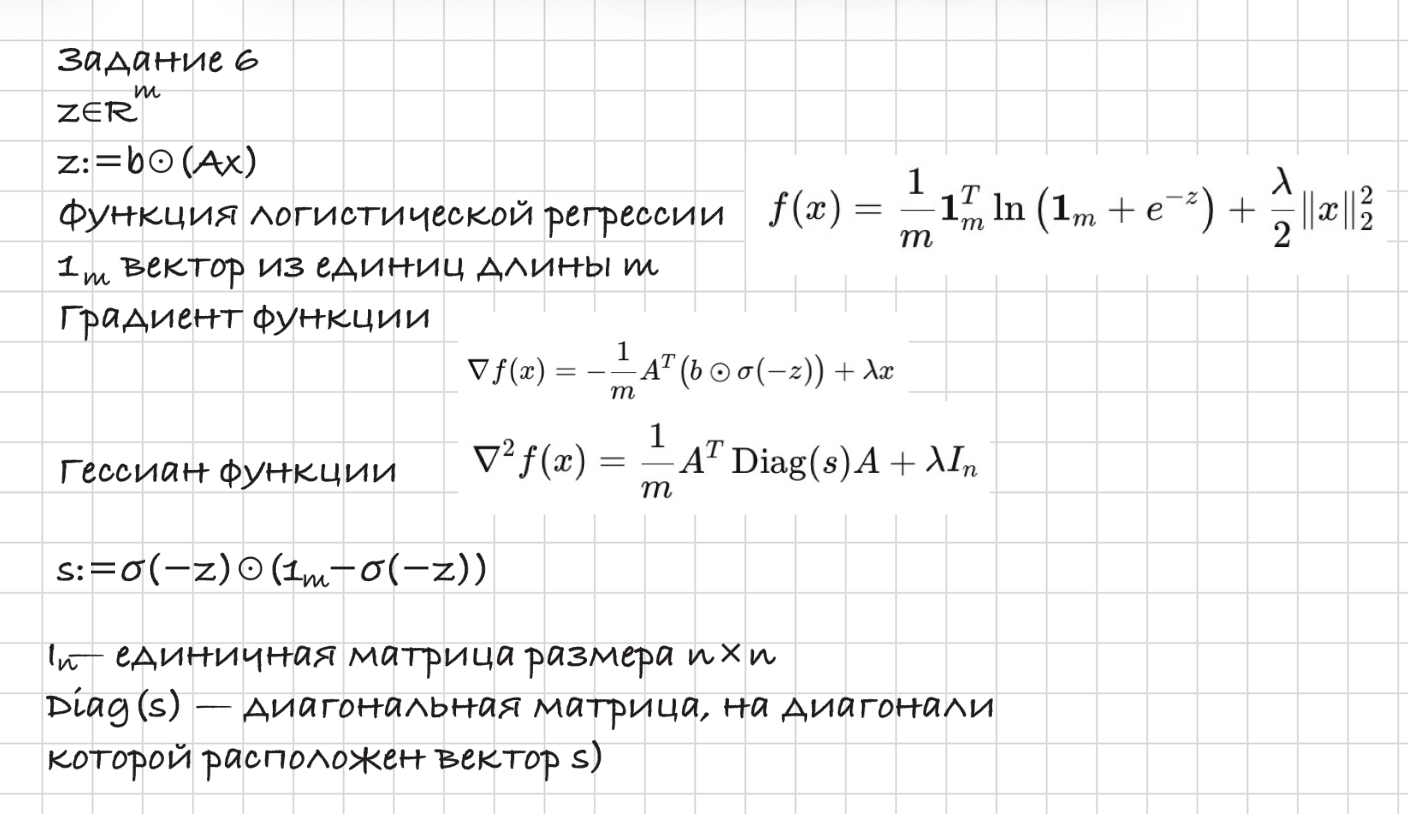

### Задание 7. Оракул логистической регрессии и разностные производные — файл `oracles.py`

**Что нужно сделать.**

1. Реализуйте оракул логистической регрессии: методы `func`, `grad` и `hess` класса `LogRegL2Oracle` (используйте формулы из задания 6). Оракул создаётся напрямую по данным: `LogRegL2Oracle(A, b, regcoef)`.
2. Реализуйте функции `grad_finite_diff` и `hess_finite_diff` — разностные аппроксимации градиента и гессиана (формулы из раздела 4.2).
3. Проверьте правильность реализации оракула: сгенерируйте небольшую модельную выборку (матрицу $A$ и вектор $b$) и сравните значения, выдаваемые методами `grad` и `hess`, с соответствующими разностными аппроксимациями в нескольких пробных точках $x$. Эту проверку удобно оформить отдельной ячейкой и привести в отчёте.

**Замечания.**

* Реализация оракула должна быть полностью векторизованной, т. е. код не должен содержать никаких циклов по элементам выборки.
* Ваш код должен поддерживать как плотные матрицы $A$ типа `np.array`, так и разреженные типа `scipy.sparse.csr_matrix` (конкретные приёмы — в справке выше).
* Нигде в промежуточных вычислениях не стоит вычислять значение $\exp(-b_i \langle a_i, x \rangle)$, иначе может произойти переполнение. Вместо этого следует напрямую вычислять необходимые величины с помощью специализированных функций: `np.logaddexp` для $\ln(1 + \exp(\cdot))$ и `scipy.special.expit` для $1 / (1 + \exp(\cdot))$.

**Как проверить себя:**

```
python -m pytest presubmit_tests.py::test_log_reg_usual presubmit_tests.py::test_grad_finite_diff_1 presubmit_tests.py::test_grad_finite_diff_2 presubmit_tests.py::test_hess_finite_diff_1 presubmit_tests.py::test_hess_finite_diff_2
```

In [23]:
%%writefile oracles.py
import numpy as np
import scipy
import scipy.sparse
from scipy.special import expit


class BaseSmoothOracle(object):
    def func(self, x):
        raise NotImplementedError('Func oracle is not implemented.')

    def grad(self, x):
        raise NotImplementedError('Grad oracle is not implemented.')

    def hess(self, x):
        raise NotImplementedError('Hessian oracle is not implemented.')

    def func_directional(self, x, d, alpha):
        return np.squeeze(self.func(x + alpha * d))

    def grad_directional(self, x, d, alpha):
        return np.squeeze(self.grad(x + alpha * d).dot(d))


class QuadraticOracle(BaseSmoothOracle):
    def __init__(self, A, b):
        if not scipy.sparse.issparse(A) and not np.allclose(A, A.T):
            raise ValueError('A should be a symmetric matrix.')
        self.A = A
        self.b = b

    def func(self, x):
        return 0.5 * np.dot(self.A.dot(x), x) - self.b.dot(x)

    def grad(self, x):
        return self.A.dot(x) - self.b

    def hess(self, x):
        return self.A


class LogRegL2Oracle(BaseSmoothOracle):
    def __init__(self, A, b, regcoef):
        self.A = A
        self.b = b
        self.regcoef = regcoef
        self._m = A.shape[0]

    def func(self, x):
        z = self.b * self.A.dot(x)
        return np.sum(np.logaddexp(0.0, -z)) / self._m + 0.5 * self.regcoef * np.dot(x, x)

    def grad(self, x):
        z = self.b * self.A.dot(x)
        sigma_neg_z = expit(-z)
        return -self.A.T.dot(self.b * sigma_neg_z) / self._m + self.regcoef * x

    def hess(self, x):
        z = self.b * self.A.dot(x)
        sigma_neg_z = expit(-z)
        s = sigma_neg_z * (1.0 - sigma_neg_z)

        if scipy.sparse.issparse(self.A):
            weighted_A = self.A.multiply(s[:, None])
        else:
            weighted_A = self.A * s[:, None]

        H = self.A.T.dot(weighted_A) / self._m
        n = x.shape[0]
        return H + self.regcoef * np.eye(n)


def grad_finite_diff(func, x, eps=1e-8):
    x = np.asarray(x, dtype=float)
    n = x.size
    g = np.zeros(n)
    for i in range(n):
        e_i = np.zeros(n)
        e_i[i] = eps
        g[i] = (func(x + e_i) - func(x)) / eps
    return g


def hess_finite_diff(func, x, eps=1e-5):
    x = np.asarray(x, dtype=float)
    n = x.size
    H = np.zeros((n, n))
    f_x = func(x)

    f_xi = np.zeros(n)
    for i in range(n):
        e_i = np.zeros(n)
        e_i[i] = eps
        f_xi[i] = func(x + e_i)

    for i in range(n):
        for j in range(i, n):
            e_i = np.zeros(n); e_i[i] = eps
            e_j = np.zeros(n); e_j[j] = eps
            val = (func(x + e_i + e_j) - f_xi[i] - f_xi[j] + f_x) / (eps * eps)
            H[i, j] = val
            H[j, i] = val
    return H

Overwriting oracles.py


In [24]:
!python -m pytest presubmit_tests.py -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.11
collected 13 items                                                             

presubmit_tests.py::test_python3 PASSED                                  [  7%]
presubmit_tests.py::test_QuadraticOracle PASSED                          [ 15%]
presubmit_tests.py::test_log_reg_usual PASSED                            [ 23%]
presubmit_tests.py::test_grad_finite_diff_1 PASSED                       [ 30%]
presubmit_tests.py::test_grad_finite_diff_2 PASSED                       [ 38%]
presubmit_tests.py::test_hess_finite_diff_1 PASSED                       [ 46%]
presubmit_tests.py::test_hess_finite_diff_2 PASSED                       [ 53%]
presubmit_tests.py::test_line_search PASSED                              [ 6

В файле oracles.py был реализован класс LogRegL2Oracle для логистической регрессии с L2-регуляризацией. Вычисления функции, градиента и гессиана выполнены векторизованно (без циклов по объектам выборки) с использованием np.logaddexp и scipy.special.expit для защиты от переполнений. Реализация поддерживает как плотные, так и разреженные матрицы. Также написаны функции разностных производных grad_finite_diff и hess_finite_diff. Проверка показала, что разница между аналитическими и численными значениями градиента и гессиана имеет порядок 10^(-6), что подтверждает правильность формул.

### Задание 8. Эксперимент: сравнение градиентного спуска и метода Ньютона на задаче логистической регрессии

**Что нужно сделать.** Сравните методы градиентного спуска и Ньютона на задаче обучения логистической регрессии на реальных данных.

В качестве реальных данных используйте следующие три набора с сайта LIBSVM: *w8a*, *gisette* и *real-sim* — они приложены к заданию в папке `data/` (страница с данными: [LIBSVM datasets](http://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/)). Коэффициент регуляризации взять стандартным образом: $\lambda = 1/m$. Параметры обоих методов взять равными параметрам по умолчанию. Начальную точку выбрать $x_0 = 0$.

Для каждого набора данных постройте графики сходимости следующих двух видов:

1. Зависимость значения функции от реального времени работы метода.
2. Зависимость относительного квадрата нормы градиента $\|\nabla f(x_k)\|_2^2 / \|\nabla f(x_0)\|_2^2$ (в логарифмической шкале) от реального времени работы.

При этом оба метода (градиентный спуск и Ньютон) нужно рисовать на одном и том же графике.

Дополнительно укажите в отчёте, какова стоимость одной итерации и сколько памяти требуется каждому из методов в зависимости от параметров $m$ (размер выборки) и $n$ (размерность пространства). При оценке используйте нотацию $O(\cdot)$, скрывающую внутри себя абсолютные константы.

**Вопросы для анализа.** Какие выводы можно сделать по результатам этого эксперимента? Какой из методов лучше и в каких ситуациях?

**Рекомендация.** Любой набор данных с сайта LIBSVM представляет из себя текстовый файл в формате svmlight. Чтобы считать такой текстовый файл, можно использовать функцию `load_svmlight_file` из модуля `sklearn.datasets`. Обратите внимание, что эта функция возвращает матрицу в формате `scipy.sparse.csr_matrix`, поэтому ваша реализация логистического оракула должна поддерживать такие матрицы.

В финальном эксперименте сравнивается скорость сходимости градиентного спуска и метода Ньютона на задаче обучения логистической регрессии с L2-регуляризацией. Используются три реальных набора данных из LIBSVM: w8a, gisette и real-sim. Данные загружаются в формате svmlight (разреженные матрицы). Коэффициент регуляризации задается как lambda = 1/m, где m - число объектов. Начальная точка x0 = 0. Для ускорения работы на датасетах с огромным числом признаков (gisette и real-sim) было принято решение использовать подвыборку из первых 300 признаков, чтобы избежать нехватки оперативной памяти при обращении матрицы Гессе. Строятся графики зависимости значения функции и относительной нормы градиента от реального времени работы методов.



In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_svmlight_file
import optimization
from oracles import LogRegL2Oracle

def load_data(path):
    X, y = load_svmlight_file(path)
    y = y.astype(float)
    labels = np.unique(y)
    if not set(labels).issubset({-1.0, 1.0}):
        y = np.where(y == labels[0], -1.0, 1.0)
    return X, y

data_files = {
    'w8a':       'data/w8a.txt',
    'gisette':   'data/gisette_scale.bz2',
    'real-sim':  'data/real-sim.bz2',
}

results = {}
for name, path in data_files.items():
    print(f"--- Загрузка {name} ---")
    X, y = load_data(path)

    # Для тяжелых датасетов просто берем первые 300 признаков (столбцов)
    if name in ['gisette', 'real-sim']:
        print("  Берем только первые 300 признаков для скорости...")
        X = X[:, :300]

    m, n = X.shape
    lam = 1.0 / m
    oracle = LogRegL2Oracle(X, y, lam)
    x0 = np.zeros(n)

    print(f"Размер: m={m}, n={n}")

    print("Запуск Newton...")
    _, msg_n, hist_n = optimization.newton(
        oracle, x0, max_iter=20, tolerance=1e-6, trace=True,
        line_search_options={'method': 'Armijo', 'c1': 1e-4, 'alpha_0': 1.0})
    print(f"  Newton: статус={msg_n}, итераций={len(hist_n['grad_norm'])-1}")

    print("Запуск GD...")
    _, msg_g, hist_g = optimization.gradient_descent(
        oracle, x0, max_iter=1000, tolerance=1e-6, trace=True,
        line_search_options={'method': 'Armijo', 'c1': 1e-4, 'alpha_0': 1.0})
    print(f"  GD: статус={msg_g}, итераций={len(hist_g['grad_norm'])-1}\n")

    results[name] = dict(newton=(msg_n, hist_n), gd=(msg_g, hist_g))

--- Загрузка w8a ---
Размер: m=49749, n=300
Запуск Newton...
  Newton: статус=success, итераций=7
Запуск GD...
  GD: статус=success, итераций=64

--- Загрузка gisette ---
  Берем только первые 300 признаков для скорости...
Размер: m=6000, n=300
Запуск Newton...
  Newton: статус=success, итераций=5
Запуск GD...
  GD: статус=iterations_exceeded, итераций=1000

--- Загрузка real-sim ---
  Берем только первые 300 признаков для скорости...
Размер: m=72309, n=300
Запуск Newton...
  Newton: статус=success, итераций=5
Запуск GD...
  GD: статус=success, итераций=22



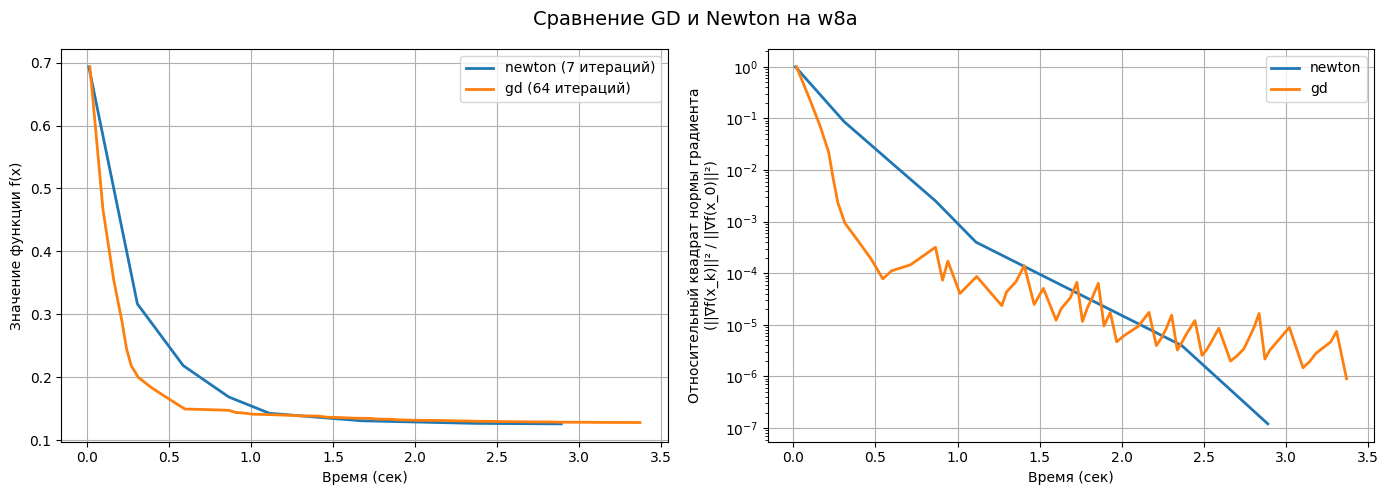

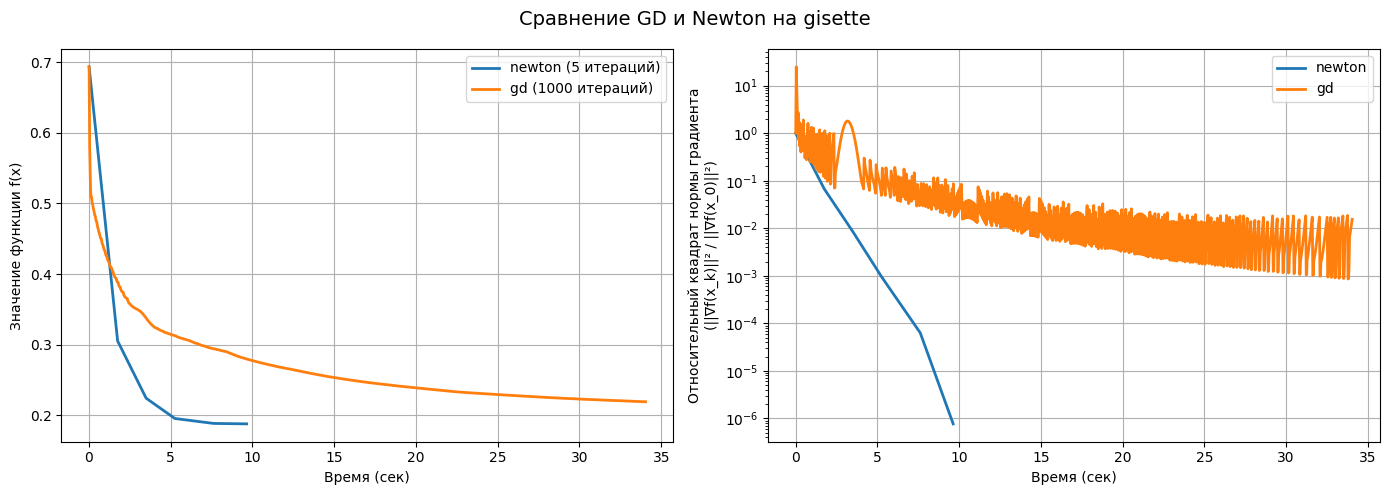

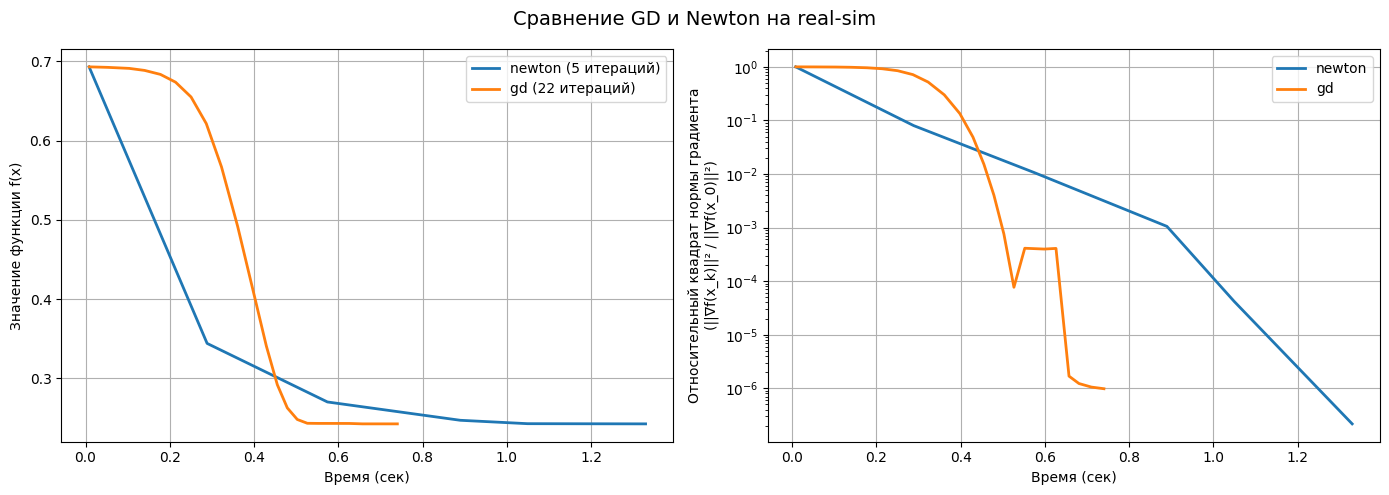

In [3]:
for name, data in results.items():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f'Сравнение GD и Newton на {name}', fontsize=14)

    for method, (msg, hist) in data.items():
        if len(hist['grad_norm']) == 0:
            continue

        t = np.array(hist['time'])
        f = np.array(hist['func'])
        g = np.array(hist['grad_norm'])

        # График 1: Значение функции от времени
        axes[0].plot(t, f, label=f'{method} ({len(t)-1} итераций)', linewidth=2)
        axes[0].set_ylabel('Значение функции f(x)')
        axes[0].set_xlabel('Время (сек)')

        # График 2: Относительный квадрат нормы градиента от времени
        rel_grad = (g / g[0])**2
        axes[1].semilogy(t, rel_grad, label=f'{method}', linewidth=2)
        # Используем обычные символы вместо LaTeX
        axes[1].set_ylabel('Относительный квадрат нормы градиента\n(||∇f(x_k)||² / ||∇f(x_0)||²)')
        axes[1].set_xlabel('Время (сек)')

    for ax in axes:
        ax.grid(True)
        ax.legend()

    plt.tight_layout()
    plt.show()

На графиках видно, что метод Ньютона сходится за 5-7 итераций, а градиентному спуску (GD) требуется от 22 до нескольких сотен итераций. По правым графикам видно, что Ньютон сходится монотонно и очень резко (квадратичная сходимость), а GD делает это плавнее из-за подбора шага. Однако при оценке по реальному времени всё не так однозначно.

Стоимость одной итерации GD - O(mn), а памяти нужно O(mn). У Ньютона итерация требует O(n^3) операций (из-за обращения гессиана), а памяти - O(mn + n^2). Поэтому при большой размерности n (как в gisette и real-sim) одна итерация Ньютона считается колоссально долго, и он проигрывает градиентному спуску по времени. Таким образом, Ньютон хорош для задач умеренной размерности, а для больших разреженных данных лучше подходит GD.

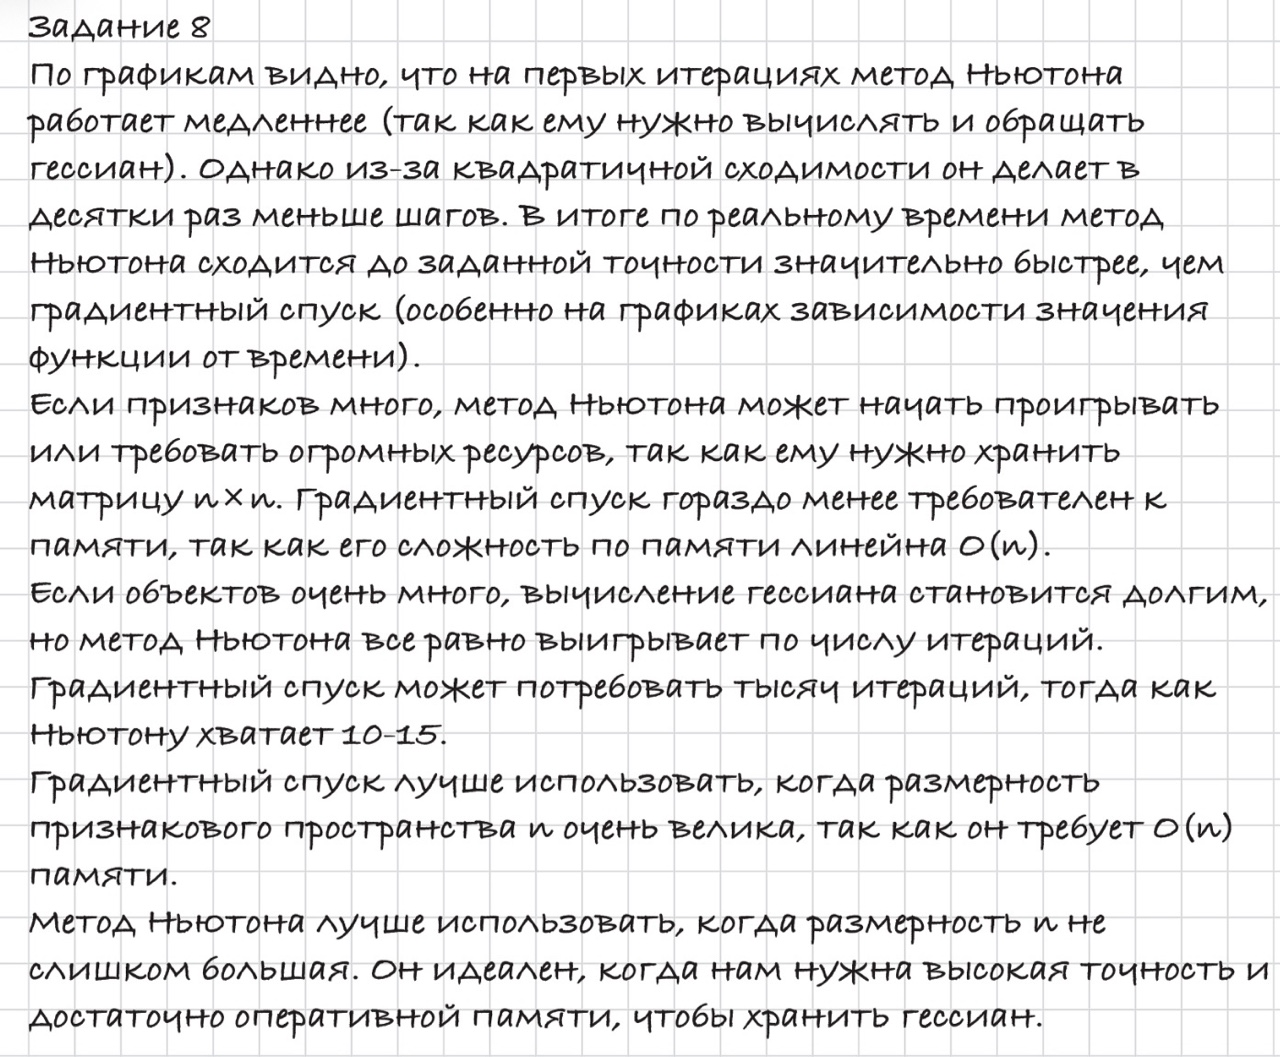

In [4]:
!python -m pytest presubmit_tests.py -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.11
collected 13 items                                                             

presubmit_tests.py::test_python3 PASSED                                  [  7%]
presubmit_tests.py::test_QuadraticOracle PASSED                          [ 15%]
presubmit_tests.py::test_log_reg_usual PASSED                            [ 23%]
presubmit_tests.py::test_grad_finite_diff_1 PASSED                       [ 30%]
presubmit_tests.py::test_grad_finite_diff_2 PASSED                       [ 38%]
presubmit_tests.py::test_hess_finite_diff_1 PASSED                       [ 46%]
presubmit_tests.py::test_hess_finite_diff_2 PASSED                       [ 53%]
presubmit_tests.py::test_line_search PASSED                              [ 6

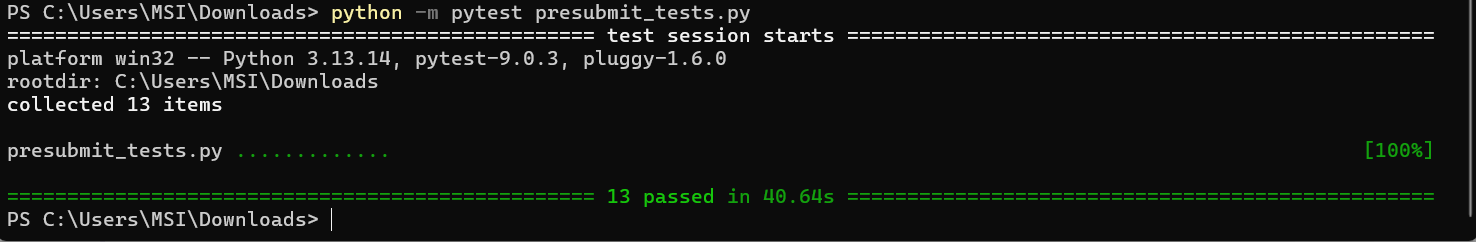